# One-site DMRG for the transverse-field Ising chain

This notebook builds toward an implementation of one-site **density matrix renormalization group (DMRG)** by working through the state representations and linear-algebra operations underlying the algorithm. The preliminary sections develop and check these ingredients before combining them into a ground-state search. Our target is the ground state of the open $N$-qubit transverse-field Ising Hamiltonian

$$
H=-J\sum_{j=0}^{N-2}Z_jZ_{j+1}-h\sum_{j=0}^{N-1}X_j,
$$

for $N\geq2$, where $J,h\in\mathbb R$ and

$$
X=\begin{pmatrix}0&1\\1&0\end{pmatrix},
\qquad
Z=\begin{pmatrix}1&0\\0&-1\end{pmatrix}.
$$

Here $X_j$ denotes $X$ on site $j$ and the identity on every other site. For example, on three qubits, $Z_0Z_1=Z\otimes Z\otimes I$ and $X_1=I\otimes X\otimes I$. The chain has open boundaries, so there is no interaction between the last and first sites.

We begin with known state vectors, interpret their entries as coefficient tensors, and factor them into **matrix product states (MPS)** using successive singular value decompositions (SVDs). Reconstructing the original vectors checks the indexing and factorization. We then use QR decompositions to establish canonical forms and move the orthogonality center without changing the represented state. These operations give orthonormal block states around the center, allowing its energy minimization to be expressed as an eigenvalue problem. Once this local update is established, we initialize an MPS directly at random and combine updates with center moves into sweeps along the chain. The final experiment compares different maximum bond dimensions against exact diagonalization for six qubits.

The result is a dense reference implementation intended for small systems. It explicitly constructs the full Hamiltonian, local embedding matrices, and state vectors used for diagnostics, exposing the algebra and allowing direct checks against independently computed results. These objects grow exponentially with the number of qubits and limit the implementation's scalability.

### Conventions

Site $0$ is the leftmost factor in $|s_0\rangle\otimes\cdots\otimes|s_{N-1}\rangle$. State-vector entries follow computational-basis order, and reshaping and flattening use NumPy's default C order. Every site tensor has axes **(left bond, physical qubit, right bond)**, including dimension-one boundary bonds.

**Before running:** use the repository's `.venv` Python environment as the notebook kernel; see the README for setup instructions.

## The objective of DMRG: minimize the energy expectation

The **Hamiltonian** $H$ is the Hermitian operator representing the system's energy. For a normalized state $|\psi\rangle$, its energy expectation is $\langle\psi|H|\psi\rangle$. For any nonzero state vector, define

$$
E(|\psi\rangle)=\frac{\langle\psi|H|\psi\rangle}{\langle\psi|\psi\rangle}.
$$

The denominator accounts for normalization, so multiplying $|\psi\rangle$ by any nonzero scalar leaves $E(|\psi\rangle)$ unchanged. Because $H$ is Hermitian, $E(| \psi \rangle)$ is real.

### Why minimize this quantity?

Let $\{|E_k\rangle\}$ be an orthonormal eigenbasis of $H$, with $H|E_k\rangle=E_k|E_k\rangle$ and $E_0$ the smallest eigenvalue. For a normalized state

$$
|\psi\rangle=\sum_k c_k|E_k\rangle,
\qquad \sum_k |c_k|^2=1,
$$

the energy expectation is

$$
E(|\psi \rangle)=\sum_k |c_k|^2E_k.
$$

It is a weighted average of the eigenvalues, so it cannot fall below the ground-state energy $E_0$. That is,

$$
E(|\psi \rangle) \geq E_0.
$$

Equality holds precisely when $|\psi\rangle$ lies in the ground-state eigenspace. Thus the smallest possible energy expectation is $E_0$, and the states that achieve it are exactly the ground states. Finding a ground state can therefore be formulated as minimizing the energy expectation over normalized states.

In this notebook, one-site DMRG seeks a low-energy matrix product state by optimizing one site tensor at a time while holding the other tensors fixed, then repeating these updates in sweeps along the chain [3, Sec. 6.3].

## Representing the Hamiltonian and obtaining an exact reference
For two qubits, in the ordered basis $(|00\rangle,|01\rangle,|10\rangle,|11\rangle)$,

$$H=-J(Z\otimes Z)-h(X\otimes I+I\otimes X)
=\begin{pmatrix}
-J&-h&-h&0\\-h&J&0&-h\\-h&0&J&-h\\0&-h&-h&-J
\end{pmatrix}.$$

Each $N$-qubit term acts on a space of dimension $2^N$, so a **dense** Hamiltonian stores all $2^N\times2^N=4^N$ entries, including zeros. For small $N$, `np.linalg.eigh(H)` gives an independent reference energy and ground-state vector against which we can check DMRG [4, numpy.linalg.eigh].

## 1. Representing quantum states as matrix product states
### From a quantum state to its coefficient tensor

In the computational basis, an $N$-qubit state has the expansion

$$
|\psi\rangle
=
\sum_{s_0,\ldots,s_{N-1}\in\{0,1\}}
\Psi_{s_0\cdots s_{N-1}}
|s_0\rangle\otimes\cdots\otimes|s_{N-1}\rangle.
$$

Each coefficient $\Psi_{s_0\cdots s_{N-1}}$ is the complex amplitude of the corresponding computational-basis vector. The position $j$ identifies the qubit, while the value $s_j\in\{0,1\}$ selects its basis vector $|0\rangle$ or $|1\rangle$.

Once the basis and qubit ordering are fixed, we can store these same $2^N$ coefficients in either of two array shapes:

- A flat **state vector** `state`, with shape $(2^N,)$.
- A **state coefficient tensor** $\Psi$, with shape $(2,\ldots,2)$, with one axis for each qubit.

The flat array stores amplitudes in computational-basis order. For three qubits, that order is

$$
|000\rangle,\ |001\rangle,\ |010\rangle,\ |011\rangle,\
|100\rangle,\ |101\rangle,\ |110\rangle,\ |111\rangle.
$$

Reshaping `state` into an array of shape $(2,2,2)$ lets us access each amplitude using the three bits of its basis label:

$$
\begin{aligned}
\Psi_{0,0,0} &= \texttt{state}[0],\\
\Psi_{0,0,1} &= \texttt{state}[1],\\
\Psi_{1,0,0} &= \texttt{state}[4],\\
\Psi_{1,1,1} &= \texttt{state}[7].
\end{aligned}
$$

For example, `state[4]` is the amplitude of the fifth basis vector, $|100\rangle$, and the same amplitude is accessed as `Psi[1, 0, 0]` in the coefficient tensor. In general, `state.reshape((2,) * N)` arranges the flat array into a coefficient tensor with one axis per qubit. The coefficients remain unchanged; reshaping changes how we index them without introducing an approximation or additional physical information [1, Tutorial 1.2; 3, Sec. 4.1.3]. 

### Factor the coefficient tensor into an MPS

An open-boundary **matrix product state (MPS)** represents the coefficient tensor as a contraction of order-three tensors arranged in a chain:

$$
\Psi_{s_0,\ldots,s_{N-1}}
=
\sum_{\alpha_1,\ldots,\alpha_{N-1}}
A^{[0]}_{0,s_0,\alpha_1}
A^{[1]}_{\alpha_1,s_1,\alpha_2}
\cdots
A^{[N-1]}_{\alpha_{N-1},s_{N-1},0}.
$$

There is one factor $A^{[j]}$ for each physical site $j$. We call these factors **site tensors**. Neighboring site tensors $A^{[j-1]}$ and $A^{[j]}$ share a contraction index $\alpha_j$. This connection is called a **bond**. Its **bond dimension** $\chi_j$ is the number of possible values of $\alpha_j$:

$$
\alpha_j \in \{0,\ldots,\chi_j-1\}.
$$

The site tensor $A^{[j]}$ therefore has shape

$$
\operatorname{shape}(A^{[j]})=(\chi_j,2,\chi_{j+1}),
$$

corresponding to its left bond, physical index, and right bond. The physical index $s_j\in\{0,1\}$ selects the computational-basis vector $|s_j\rangle$ at site $j$. The bond indices are summed-over factorization coordinates; they do not label additional physical qubits. At the boundaries, we set $\chi_0=\chi_N=1$. We retain these dimension-one axes so that every site tensor has three axes. Their indices have only one possible value, written as $0$ in the contraction above to match NumPy indexing.

To see why this is called a “matrix product state”, fix the physical indices $s_0,\ldots,s_{N-1}$. Each slice $A^{[j]}[:,s_j,:]$ is then a $\chi_j\times\chi_{j+1}$ matrix. Multiplying these matrices along the chain gives a $1\times1$ matrix whose single entry is the coefficient $\Psi_{s_0,\ldots,s_{N-1}}$.

With sufficiently large bond dimensions, this representation is exact. Restricting the bond dimensions can require an approximation to the original coefficient tensor. Across the cut between sites $j-1$ and $j$, a state's **Schmidt rank** is the rank of the coefficient matrix obtained by grouping the physical indices to the left into its row index and those to the right into its column index. An MPS with bond dimension $\chi_j$ at this cut represents a state with Schmidt rank at most $\chi_j$ [2, Matrix Product State / Tensor Train; 3, Sec. 4.1.3].

### Construct the MPS by successive SVDs

We extract one site tensor at a time, passing the remaining coefficients to the next step. Initially, the remainder is the full coefficient tensor with a dimension-one left bond:

$$
R^{[0]}_{0s_0\cdots s_{N-1}}=\Psi_{s_0\cdots s_{N-1}}.
$$

At iteration $j$, for $j=0,\ldots,N-2$, the remainder is $R^{[j]}_{\alpha_j,s_j,\ldots,s_{N-1}}$. Reshape it into a matrix by grouping the left bond and current physical index into a row index, and the remaining physical indices into a column index. The entries are related by

$$
M^{[j]}_{(\alpha_j,s_j),(s_{j+1},\ldots,s_{N-1})}
=
R^{[j]}_{\alpha_j,s_j,\ldots,s_{N-1}}.
$$

There are $\chi_j$ choices for $\alpha_j$ and two choices for $s_j$, giving $2\chi_j$ rows. The remaining $N-j-1$ binary indices give $2^{N-j-1}$ columns. Thus

$$
\operatorname{shape}(M^{[j]})=(2\chi_j,2^{N-j-1}).
$$

Compute the economy SVD, using `np.linalg.svd(matrix, full_matrices=False)`:

$$
M^{[j]}=U\Sigma V^\dagger.
$$

If $q=\min(2\chi_j,2^{N-j-1})$, NumPy returns [4, numpy.linalg.svd]:

- $U$ with shape $(2\chi_j,q)$;
- a one-dimensional array of singular values with shape $(q,)$;
- $V^\dagger$ with shape $(q,2^{N-j-1})$.

The diagonal matrix $\Sigma$ has those singular values on its diagonal. Economy SVD can include zero singular values, so $q$ need not equal the matrix rank.

Choose the number of retained directions:

$$
k=
\begin{cases}
q, & \text{without a bond cap},\\
\min(q,\texttt{max\_bond}), & \text{with a bond cap}.
\end{cases}
$$

Set $\chi_{j+1}=k$, then form the next site tensor and remainder:

1. Reshape the first $k$ columns of $U$ into $A^{[j]}$ with shape $(\chi_j,2,k)$.
2. Pass $\Sigma_{:k,:k}V^\dagger_{:k,:}$ to the next iteration as the remainder. This matrix has shape $(k,2^{N-j-1})$: its row index becomes the next left bond $\alpha_{j+1}$, while its columns correspond to the remaining physical indices $(s_{j+1},\ldots,s_{N-1})$.

In components, this step gives

$$
R^{[j]}_{\alpha_j s_j\cdots s_{N-1}}
\approx
\sum_{\alpha_{j+1}}
A^{[j]}_{\alpha_j s_j\alpha_{j+1}}
R^{[j+1]}_{\alpha_{j+1}s_{j+1}\cdots s_{N-1}}.
$$

The equality is exact if no nonzero singular values are discarded. Otherwise, keeping the largest $k$ singular values gives the best rank-at-most-$k$ matrix approximation in Frobenius norm at this step (Recall: the Frobenius norm is the square root of the sum of the squared absolute values of all array entries. For a quantum state's coefficients arranged as a column vector in an orthonormal basis, it equals the usual Euclidean norm). Successive truncations do not generally give the globally best MPS at the chosen bond cap [1, Tutorials 2.4 and 4.1; 3, Sec. 4.1.1].

After extracting sites $0,\ldots,N-2$, reshape the final remainder into the last site tensor, with shape $(\chi_{N-1},2,1)$.

The retained columns of $U$ are orthonormal, making every site tensor before the last left-normalized. The resulting MPS has its **orthogonality center** at the last site, whose tensor contains the remaining coefficients. In this form, the Frobenius norm of the last tensor equals the norm of the represented state; the next section explains this identity and the canonical-form terminology. Discarding nonzero singular values can reduce that norm, and `state_to_mps` does not renormalize the output.

### Reconstruct the state

To reconstruct the state coefficient tensor from an MPS, contract neighboring site tensors along their shared bond indices. This leaves the physical indices $s_0,\ldots,s_{N-1}$, and flattening the resulting tensor in C order returns the state vector. The function `mps_to_state` in `src/ising_dmrg/mps.py` implements this procedure. When the MPS was constructed without truncation, the reconstructed vector should agree with the original input up to floating-point error.

We begin with a known vector so that reconstruction can be compared directly with its input coefficients. This checks the factorization and reconstruction on a concrete example before we use these functions in an optimization. DMRG will instead begin directly with a random MPS, without knowing the ground-state coefficients.

We leave the example vector unnormalized so that reconstruction and the subsequent QR moves also check preservation of its scale.

In [1]:
import numpy as np
from ising_dmrg.mps import (
    canonicalize_at_zero,
    mps_to_state,
    random_mps,
    shift_left,
    shift_right,
    state_to_mps,
)

rng = np.random.default_rng(137)
state = rng.normal(size=16) + 1j * rng.normal(size=16)

tensors = state_to_mps(state)
reconstructed = mps_to_state(tensors)
max_error = np.max(np.abs(reconstructed - state))

print("Site shapes:", [tensor.shape for tensor in tensors])
print(f"Maximum reconstruction error: {max_error:.3e}")
print(f"Input norm: {np.linalg.norm(state):.8f}")
print(f"Reconstructed norm: {np.linalg.norm(reconstructed):.8f}")

Site shapes: [(1, 2, 2), (2, 2, 4), (4, 2, 2), (2, 2, 1)]
Maximum reconstruction error: 1.964e-15
Input norm: 5.74790823
Reconstructed norm: 5.74790823


## 2. Moving the center of orthogonality

A site tensor $A_{\alpha s\beta}$ is **left-normalized** when 

$$\sum_{\alpha,s}\overline{A_{\alpha s\beta}}A_{\alpha s\gamma} =\delta_{\beta\gamma}.$$

Equivalently, the matrix with rows $(\alpha,s)$ and columns $\beta$ has orthonormal columns. A tensor $B_{\alpha s\beta}$ is **right-normalized** when

$$\sum_{s,\beta}B_{\alpha s\beta}\overline{B_{\gamma s\beta}} =\delta_{\alpha\gamma};$$

the matrix with rows $\alpha$ and columns $(s,\beta)$ has orthonormal rows. These properties depend on the grouping of indices, not just the tensor shape. For a normalized state, an MPS is **left-canonical** when every site tensor is left-normalized, and **right-canonical** when every site tensor is right-normalized. A left-canonical MPS can be regarded as having its orthogonality center at the last site, while a right-canonical MPS can be regarded as centered at the first site. For an unnormalized state, the corresponding boundary center tensor carries the overall norm and need not satisfy the local normalization condition [3, Sec. 4.1.3(i)–(ii), Eqs. (38) and (45)].

An MPS is in **mixed-canonical form centered at site $i$** when all site tensors before $i$ are left-normalized and all site tensors after $i$ are right-normalized. The center tensor is not required to satisfy either normalization condition. This site-centered form follows by absorbing the central singular-value matrix into a neighboring tensor in the bond-centered construction [3, Sec. 4.1.3(iii), Eq. (53) and Fig. 8].

### Gauge freedom and QR center moves

MPS gauge transformations change the internal bond coordinates while preserving the represented state. To express this freedom, reshape two neighboring site tensors into compatible matrices $M$ and $S$, with their shared bond labeling the columns of $M$ and the rows of $S$. An invertible matrix $G$ multiplied along the shared bond axis can be absorbed into the two factors in compensating ways:

$$
(MG)(G^{-1}S)=M(GG^{-1})S=MS.
$$

Thus the factors can change while their contraction remains fixed. Canonicalization uses this freedom to impose orthonormality conditions on the site tensors, giving useful coordinates for subsequent calculations [1, Tutorial 3.2; 3, Sec. 4.1.3, Eq. (57)].

Starting from mixed-canonical form centered at site $i$, move the center right by reshaping its tensor into $M$ with shape $(2\chi_i,\chi_{i+1})$ and computing the reduced QR decomposition $M=QR$. Reshape $Q$ into the new site tensor and absorb $R$ into the right neighbor along their shared bond. Writing that neighbor as a compatible matrix $S$, the contraction is preserved because

$$
MS=(QR)S=Q(RS).
$$

Since $Q^\dagger Q=I$, the tensor at site $i$ is now left-normalized, and the updated tensor at site $i+1$ becomes the center. When $R$ is square and invertible, this is precisely the gauge transformation above with $G=R^{-1}$: the new factors are $Q=MR^{-1}$ and $RS$. The implementation obtains these factors through QR and multiplication, without computing an inverse.

To move left, reshape the center tensor into $M$ with shape $(\chi_i,2\chi_{i+1})$ and factor $M^\dagger=QR$. Taking the adjoint gives $M=R^\dagger Q^\dagger$, so retain reshaped $Q^\dagger$ at site $i$ and absorb $R^\dagger$ into the previous tensor. Writing the previous tensor as a compatible matrix $P$, we have

$$
PM=P(R^\dagger Q^\dagger)=(PR^\dagger)Q^\dagger.
$$

The retained tensor is right-normalized because $Q^\dagger$ has orthonormal rows, and the updated tensor at site $i-1$ becomes the center. Both directions preserve the represented state without singular-value truncation. These QR procedures are described in [1, Tutorial 3.3; 3, Secs. 4.1.2 and 4.4].

The product identities remain valid when $R$ is singular or rectangular, since they do not require its inverse. If reduced QR decreases a bond dimension, it also removes redundant bond coordinates while preserving the contraction exactly. That dimension reduction is an exact refactorization rather than an invertible gauge transformation within the original bond space.

### Why the center carries the norm

Assume the MPS is in mixed-canonical form centered at site $i$, and write $\theta=A^{[i]}$ for the center tensor. Contracting the site tensors before $i$ defines left block states $|L_\alpha\rangle$, while contracting those after $i$ defines right block states $|R_\beta\rangle$. The left- and right-normalized conditions make each set orthonormal, so the product states $|L_\alpha\rangle\otimes|s\rangle\otimes|R_\beta\rangle$ are also orthonormal. The entries of $\theta$ are the coefficients of the full state in this orthonormal set:

$$
|\psi\rangle
=
\sum_{\alpha,s,\beta}
\theta_{\alpha,s,\beta}
|L_\alpha\rangle\otimes|s\rangle\otimes|R_\beta\rangle.
$$

When we compute the squared norm, orthonormality eliminates the cross terms, leaving

$$
\langle\psi|\psi\rangle
=
\sum_{\alpha,s,\beta}|\theta_{\alpha,s,\beta}|^2
=
\|\theta\|_F^2.
$$

The global vector norm therefore equals the center tensor's Frobenius norm. For a nonzero state, dividing the center tensor by its Frobenius norm normalizes the represented state while leaving all other site tensors unchanged. This identity relies on the surrounding tensors satisfying the canonical conditions; the Frobenius norm of an arbitrary site tensor need not equal the global state norm [1, Tutorial 3.4; 3, Sec. 4.1.3].

Our function `canonicalize_at_zero` works from right to left through sites $N-1,N-2,\ldots,1$. Each step makes the current site tensor right-normalized and absorbs the remaining factor into its left neighbor. After this pass, all sites after $0$ are right-normalized, so the MPS is in mixed-canonical form centered at site $0$. Setting `normalize=False` preserves the input state's scale, while the default `normalize=True` additionally divides the final center tensor by its Frobenius norm. With normalization enabled, the boundary tensor at site $0$ also satisfies the right-normalization condition, making the returned MPS fully right-canonical.

In the following demonstration, we first place the orthogonality center at site $0$ without renormalizing the state, then move it to the last site and back. After each move, we reconstruct the state vector, compare it with the initial reference, and record the center tensor's Frobenius norm. The reconstruction error should remain near floating-point precision, while the center norm should remain equal to the global state norm, illustrating that the QR moves change the MPS factors while preserving their contraction.

In [2]:
from IPython.display import Markdown, display


def center_diagnostics(tensors, center, reference_state):
    """Return the center index, reconstruction error, and center tensor norm."""
    state = mps_to_state(tensors)
    return (center, np.linalg.norm(state - reference_state),np.linalg.norm(tensors[center]))


baseline = mps_to_state(tensors)
centered = canonicalize_at_zero(tensors, normalize=False)
current = centered
rows = [center_diagnostics(current, 0, baseline)]

for site in range(len(current) - 1):
    current = shift_right(current, site)
    rows.append(center_diagnostics(current, site + 1, baseline))

for site in range(len(current) - 1, 0, -1):
    current = shift_left(current, site)
    rows.append(center_diagnostics(current, site - 1, baseline))

table = [
    "| Center | Reconstruction error | Center norm |",
    "|---:|---:|---:|",
]
table += [
    f"| {center} | {error:.3e} | {norm:.8f} |"
    for center, error, norm in rows
]

display(Markdown("\n".join(table)))
print("Global norm:", np.linalg.norm(baseline))

| Center | Reconstruction error | Center norm |
|---:|---:|---:|
| 0 | 2.658e-15 | 5.74790823 |
| 1 | 2.876e-15 | 5.74790823 |
| 2 | 4.011e-15 | 5.74790823 |
| 3 | 4.318e-15 | 5.74790823 |
| 2 | 4.179e-15 | 5.74790823 |
| 1 | 4.225e-15 | 5.74790823 |
| 0 | 4.273e-15 | 5.74790823 |

Global norm: 5.747908233449979


## 3. Optimize one site
Assume the MPS is in mixed-canonical form centered at site $i$, and hold every other site tensor fixed. We call these tensors to the left and right of the center the **exterior tensors**. They determine the block states $|L_\alpha\rangle$ and $|R_\beta\rangle$, while the entries of the center tensor $\theta:=A^{[i]}$ are the coefficients we vary. With the exterior tensors fixed, the product states $|L_\alpha\rangle\otimes|s\rangle\otimes|R_\beta\rangle$ span a linear subspace of the full Hilbert space, and the center coefficients specify a vector within that subspace.

### From the center tensor to the full state

The expansion from section 2 expresses the full state as a linear combination of the fixed product states $|L_\alpha\rangle\otimes|s\rangle\otimes|R_\beta\rangle$, with coefficients supplied by the center tensor. Let $\boldsymbol{\theta}$ denote this tensor flattened into a vector in C order. Collecting the product states into the columns of a matrix $W_i$ turns the expansion into matrix multiplication:

$$
|\psi\rangle
=
\sum_{\alpha,s,\beta}
\theta_{\alpha,s,\beta}
|L_\alpha\rangle\otimes|s\rangle\otimes|R_\beta\rangle
=
W_i\boldsymbol{\theta}.
$$

We call $W_i$ the **local embedding** because it maps the center's coefficient space into the full $N$-qubit state space. Its construction depends on the fixed exterior tensors and the center's dimensions. Changing the center coefficients therefore changes $\boldsymbol{\theta}$ while leaving $W_i$ fixed.

To construct this matrix explicitly, let $x=(s_0,\ldots,s_{i-1})$ and $y=(s_{i+1},\ldots,s_{N-1})$ denote computational-basis strings for the left and right blocks. Define their coefficient arrays $L$ and $R$ by

$$
|L_\alpha\rangle=\sum_x L_{x,\alpha}|x\rangle,
\qquad
|R_\beta\rangle=\sum_y R_{\beta,y}|y\rangle.
$$

The arrays have shapes $(2^i,\chi_i)$ and $(\chi_{i+1},2^{N-i-1})$, respectively. At a boundary, the empty block has a single basis state and coefficient $1$. There are $D_i=2\chi_i\chi_{i+1}$ center coefficients, so $W_i$ has $D_i$ columns and $2^N$ rows.

Order the columns in the same way as the flattened center tensor: $\beta$ varies fastest, followed by $s$, then $\alpha$. The triple $(\alpha,s,\beta)$ corresponds to column number $q=(2\alpha+s)\chi_{i+1}+\beta$, and that column contains the computational-basis coefficients of the product state

$$
W_i[:,q]
=
|L_\alpha\rangle\otimes|s\rangle\otimes|R_\beta\rangle.
$$

For a row labeled by the full computational-basis string $(x,t,y)$, the corresponding matrix entry is

$$
(W_i)_{(x,t,y),q}
=
L_{x,\alpha}\delta_{t,s}R_{\beta,y}.
$$

Canonical form makes the left and right block states orthonormal. Together with the orthonormal computational basis at site $i$, this gives

$$
\langle L_\alpha,s,R_\beta|L_\gamma,t,R_\delta\rangle
=
\delta_{\alpha,\gamma}\delta_{s,t}\delta_{\beta,\delta},
\qquad
W_i^\dagger W_i=I_{D_i}.
$$

Thus $W_i$ is an **isometry**: it preserves inner products and norms when mapping center coefficients to full state vectors. In particular, $\|W_i\boldsymbol{\theta}\|_2=\|\boldsymbol{\theta}\|_2$, recovering the center-norm identity from section 2. These orthonormal block coordinates are the basis for the local optimization [3, Secs. 4.1.3 and 6.2].

Our function `local_embedding` constructs $W_i$ from the MPS tensors and the chosen site. For example, with four qubits, center $i=1$, and adjacent bond dimensions both equal to $2$, we have $D_i=8$ and $W_i$ has shape $(16,8)$. Its columns span the eight-dimensional subspace of states attainable by changing this center while holding the exterior tensors fixed.

### The effective Hamiltonian and local minimizer

With the exterior tensors fixed, define the **effective Hamiltonian** $H_{\mathrm{eff}}=W_i^\dagger H W_i$. This $D_i\times D_i$ Hermitian matrix describes the energy within the subspace accessible by varying the center tensor. Substituting $|\psi\rangle=W_i\boldsymbol{\theta}$ into the energy expectation and using $W_i^\dagger W_i=I$ gives

$$
E(|\psi\rangle)
=
\frac{\boldsymbol{\theta}^\dagger W_i^\dagger H W_i\boldsymbol{\theta}}
{\boldsymbol{\theta}^\dagger W_i^\dagger W_i\boldsymbol{\theta}}
=
\frac{\boldsymbol{\theta}^\dagger H_{\mathrm{eff}}\boldsymbol{\theta}}
{\boldsymbol{\theta}^\dagger\boldsymbol{\theta}}.
$$

We can restrict the minimization to normalized center vectors because multiplying $\boldsymbol{\theta}$ by a nonzero scalar leaves this energy unchanged. To see why the minimization becomes an eigenvalue problem, let $\{v_k\}$ be an orthonormal eigenbasis of $H_{\mathrm{eff}}$, with $H_{\mathrm{eff}}v_k=\lambda_kv_k$. Writing

$$
\boldsymbol{\theta}=\sum_k c_kv_k,
\qquad
\sum_k|c_k|^2=1,
$$

gives

$$
E(|\psi\rangle)
=
\boldsymbol{\theta}^\dagger H_{\mathrm{eff}}\boldsymbol{\theta}
=
\sum_k|c_k|^2\lambda_k
\geq \lambda_{\min}.
$$

This weighted average cannot fall below the smallest eigenvalue $\lambda_{\min}$, and choosing $\boldsymbol{\theta}$ to be a corresponding normalized eigenvector attains that bound. Thus the minimum energy achievable with these exterior tensors fixed is $E_{\mathrm{local}}=\lambda_{\min}$, and a minimizing center vector satisfies

$$
H_{\mathrm{eff}}\boldsymbol{\theta}_{\min}
=
E_{\mathrm{local}}\boldsymbol{\theta}_{\min}.
$$

Reshape $\boldsymbol{\theta}_{\min}$ to $(\chi_i,2,\chi_{i+1})$ and replace the center tensor. The updated full state is normalized because $W_i$ preserves norms. Here “local” refers to optimizing one center tensor; $E_{\mathrm{local}}$ remains the energy expectation of the full Hamiltonian $H$. This is the one-site DMRG optimization step [3, Sec. 6.3].

This update minimizes the energy with the exterior tensors fixed. Optimizing the other tensors can lower the energy further, so we repeat the updates in sweeps along the chain.

In this demonstration, we use a four-qubit Ising chain and a random MPS with maximum bond dimension $2$, placing the orthogonality center at site $1$. We check that $W$ reconstructs the full state from the center coefficients and satisfies $W^\dagger W=I$, then optimize that center while holding the surrounding tensors fixed. The energy should decrease or remain unchanged up to numerical precision, and comparison with the exact ground-state energy shows how close this single update comes to the global minimum.

In [3]:
from ising_dmrg.hamiltonian import ising_hamiltonian, energy_expectation
from ising_dmrg.solver import local_embedding, optimize_site

H_demo = ising_hamiltonian(4)
initial_demo = shift_right(random_mps(4, max_bond=2, seed=314), 0)
W = local_embedding(initial_demo, site=1)
theta = initial_demo[1].reshape(-1)
energy_before = energy_expectation(H_demo, mps_to_state(initial_demo))
updated, energy_after = optimize_site(initial_demo, H_demo, site=1)
energy_after = energy_expectation(H_demo, mps_to_state(updated))

print("Embedding shape:", W.shape)
print("Embedding reconstruction error:",
      np.linalg.norm(W @ theta - mps_to_state(initial_demo)))
print("Isometry error:", np.linalg.norm(W.conj().T @ W - np.eye(W.shape[1])))
print("Energy before:", energy_before)
print("Energy after:", energy_after)
print("Exact ground energy:", np.linalg.eigvalsh(H_demo)[0])

Embedding shape: (16, 8)
Embedding reconstruction error: 1.9643397710770935e-16
Isometry error: 2.327624008845873e-15
Energy before: 1.743070173660117
Energy after: -4.058648265319842
Exact ground energy: -4.758770483143631


## 4. Sweep and validate
We now combine one-site optimizations with QR moves of the orthogonality center into repeated DMRG sweeps, then assess how closely the resulting state approximates the ground state. Begin with an MPS in mixed-canonical form centered at site $0$. Optimize the center tensor, move the center one site to the right by QR, and optimize again, continuing through the last site. Then move left and optimize each site through site $0$. In this notebook, one **full sweep** includes both directions, giving the optimization order

$$
0,1,\ldots,N-1,N-2,\ldots,0.
$$

Each full sweep performs $2N-1$ local optimizations and ends centered at site $0$. The QR moves preserve the represented state and its energy. Each local optimization finds the lowest-energy center tensor with the surrounding tensors fixed, so the energy cannot increase in exact arithmetic; small numerical increases can occur from floating-point roundoff.

The solver stores the initial energy and the energy after each full sweep in `energies`, while `local_energies` records the energy after every local optimization. Let $E_k$ denote the energy after sweep $k$ and $\varepsilon$ the stopping tolerance. After at least two sweeps, the solver stops when

$$
|E_k-E_{k-1}|\leq\varepsilon\max(1,|E_k|),
$$

or when it reaches the maximum number of sweeps. The flag `energy_converged` reports whether this energy-change criterion was met. Small changes between sweeps indicate an energy plateau, which can occur above the true ground-state energy, so we also check the resulting state independently.

### Independent diagnostics

Let $|\psi\rangle$ be the normalized state returned by the solver, and let $E_0$ and $|\psi_0\rangle$ be the ground-state energy and a normalized ground-state vector obtained by exact diagonalization. We evaluate the **energy error**, **residual**, and **fidelity**:

$$
\Delta E=E(|\psi\rangle)-E_0,\qquad
r=\|H|\psi\rangle-E(|\psi\rangle)|\psi\rangle\|_2,\qquad
F=|\langle\psi_0|\psi\rangle|^2.
$$

The energy error measures how far the computed energy lies above the known minimum, while the residual measures how closely the state satisfies the eigenvalue equation. An excited eigenstate also has zero residual, so we check both quantities to assess whether the result approximates a ground state. Fidelity measures agreement with the exact reference state and is insensitive to a global phase; the diagnostic normalizes both vectors before this comparison. For our benchmark parameters, the ground state is unique up to a global phase, so fidelity near $1$ indicates close agreement with the ground state.

The four-site demonstration below uses a maximum bond dimension of $4$, enough to represent any four-qubit state exactly. We display its numerical diagnostics here, while automated tests check the energy, residual, fidelity, state normalization, canonical form, and energy histories.

In [4]:
from ising_dmrg.solver import run_dmrg
from ising_dmrg.hamiltonian import state_diagnostics

H_check = ising_hamiltonian(4)
exact_values, exact_vectors = np.linalg.eigh(H_check)
result = run_dmrg(H_check, random_mps(4, max_bond=4, seed=414), max_sweeps=8)
diagnostics = state_diagnostics(
    H_check, mps_to_state(result["mps"]), exact_vectors[:, 0])
print("Energy error:", diagnostics["energy"] - exact_values[0])
print("Residual:", diagnostics["residual"])
print(f"Fidelity: {diagnostics['fidelity']:.12f}")
print("Sweeps:", result["sweeps"])

Energy error: 0.0
Residual: 4.089719783698863e-15
Fidelity: 1.000000000000
Sweeps: 2


## 5. Bond dimension and accuracy

We now compare DMRG results at different bond caps against exact diagonalization to examine how bond dimension affects accuracy. We use $N=6$, $J=h=1$, and caps $\chi_{\max}\in\{1,2,4,8\}$, with seed $500+\chi_{\max}$ for each run. Each run allows up to $24$ full sweeps with stopping tolerance $\varepsilon=10^{-11}$.

Cap $1$ restricts the MPS to a product state. Across a cut separating the first $j$ qubits from the remaining $N-j$, the Schmidt rank is at most $\min(2^j,2^{N-j})$. For six qubits, these bounds are $2,4,8,4,2$, so cap $8$ permits an exact representation of any six-qubit state, with smaller bonds sufficient near the ends.

Increasing the cap enlarges the family of representable states, so the lowest energy attainable within that family cannot increase. Individual DMRG runs may stop above these minima, however, so their computed energies need not improve monotonically across caps. One-site updates do not increase bond dimensions, so each run begins with bonds chosen for its cap. With one initialization per cap, this experiment compares accuracy for these runs without assessing sensitivity to initialization.

In [5]:
import matplotlib.pyplot as plt

N, J, h = (6, 1.0, 1.0)
H = ising_hamiltonian(N, J=J, h=h)
exact_values, exact_vectors = np.linalg.eigh(H)
E0, ground = (float(exact_values[0]), exact_vectors[:, 0])
caps = (1, 2, 4, 8)
benchmark = {}
rows = ['| Bond cap | Seed | Sweeps | Energy | E - E0 | Fidelity | Residual | Plateau |', '|---:|---:|---:|---:|---:|---:|---:|:---:|']
for cap in caps:
    seed = 500 + cap
    result = run_dmrg(H, random_mps(N, cap, seed=seed), max_sweeps=24, energy_tol=1e-11)
    final_state = mps_to_state(result['mps'])
    diagnostics = state_diagnostics(H, final_state, ground)
    benchmark[cap] = {'result': result, 'diagnostics': diagnostics, 'seed': seed}
    rows.append(f"| {cap} | {seed} | {result['sweeps']} | {diagnostics['energy']:.10f} | {diagnostics['energy'] - E0:.3e} | {diagnostics['fidelity']:.8f} | {diagnostics['residual']:.3e} | {result['energy_converged']} |")
print(f'Exact ground energy: {E0:.12f}')
display(Markdown('\n'.join(rows)))

Exact ground energy: -7.296229810559


| Bond cap | Seed | Sweeps | Energy | E - E0 | Fidelity | Residual | Plateau |
|---:|---:|---:|---:|---:|---:|---:|:---:|
| 1 | 501 | 7 | -6.9024965319 | 3.937e-01 | 0.46908064 | 7.676e-01 | True |
| 2 | 502 | 4 | -7.2943159362 | 1.914e-03 | 0.99950652 | 9.507e-02 | True |
| 4 | 504 | 3 | -7.2962297287 | 8.181e-08 | 0.99999999 | 7.305e-04 | True |
| 8 | 508 | 2 | -7.2962298106 | 2.665e-15 | 1.00000000 | 6.184e-15 | True |

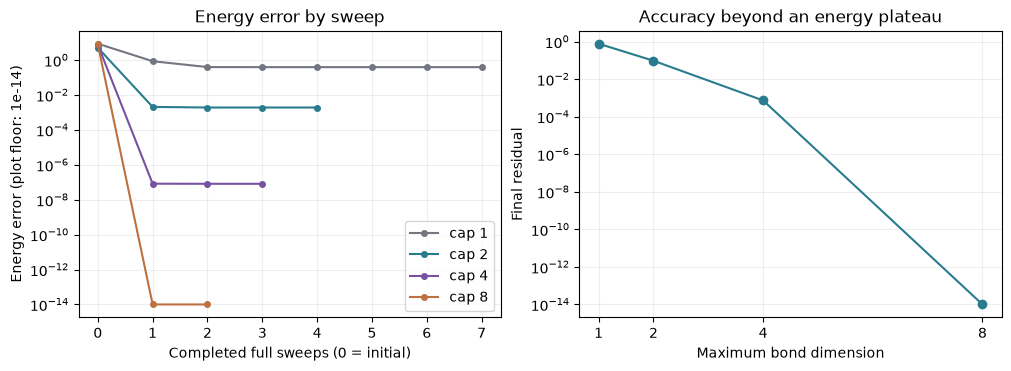

In [6]:
colors = ("#737680", "#287c8e", "#7652a1", "#bd7040")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
for cap, color in zip(caps, colors):
    history = benchmark[cap]["result"]["energies"]
    axes[0].semilogy(
        np.arange(len(history)), np.maximum(history - E0, 1e-14),
        "o-", color=color, label=f"cap {cap}", markersize=4,
    )
axes[0].set(xlabel="Completed full sweeps (0 = initial)",
            ylabel="Energy error (plot floor: 1e-14)", title="Energy error by sweep")
axes[0].legend()
axes[1].semilogy(
    caps, [max(benchmark[cap]["diagnostics"]["residual"], 1e-14) for cap in caps],
    "o-", color=colors[1],
)
axes[1].set(xticks=caps, xlabel="Maximum bond dimension",
            ylabel="Final residual", title="Accuracy beyond an energy plateau")
for axis in axes:
    axis.grid(alpha=0.2)
display(fig)
plt.close(fig)

Both plots display values below $10^{-14}$ at $10^{-14}$ so they remain visible on logarithmic axes. The table reports the computed values without this plotting adjustment.

### Reading the results

Meeting the energy-plateau criterion means that the energy changed little between sweeps; it does not establish that the ground state was found. Cap $1$ retains an appreciable energy error and residual, while cap $4$ substantially reduces the energy error. Cap $8$ agrees with exact diagonalization to numerical precision and has a residual near zero.

## Scope and possible extensions

This solver constructs full Hamiltonians, explicit embedding matrices, and state vectors for diagnostics. Their exponential growth limits the implementation to small systems, where exact diagonalization supplies a reference for checking the results.

A possible extension is to represent the Hamiltonian itself as a chain of tensors and compute the local energy equations through partial contractions of the tensors on each side of the center. This would replace the full arrays used here. Two-site updates could also allow bond dimensions to change during optimization. These are directions for further study and implementation [3, Secs. 5 and 6].

## References

1. Glen Evenbly. **Tensors.net**. [Website](https://www.tensors.net/); [Tutorial 1: Tensor Contractions](https://www.tensors.net/tutorial-1); [Tutorial 2: Tensor Decompositions](https://www.tensors.net/tutorial-2); [Tutorial 3: Gauge Freedom](https://www.tensors.net/tutorial-3); [Tutorial 4: Canonical Forms](https://www.tensors.net/tutorial-4).

2. **TensorNetwork.org**. [Website](https://tensornetwork.org/); [Matrix Product State / Tensor Train](https://tensornetwork.org/mps/); [Density Matrix Renormalization Group Algorithm](https://tensornetwork.org/mps/algorithms/dmrg/).

3. Ulrich Schollwöck (2011). **The density-matrix renormalization group in the age of matrix product states**. *Annals of Physics*, 326. [arXiv:1008.3477](https://arxiv.org/abs/1008.3477); [PDF](https://arxiv.org/pdf/1008.3477).

4. **NumPy documentation**. [`numpy.reshape`](https://numpy.org/doc/stable/reference/generated/numpy.reshape.html); [`numpy.linalg.svd`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html); [`numpy.linalg.qr`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.qr.html); [`numpy.linalg.eigh`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.eigh.html).